### Option C — frozen EKF + learned leftover noise

Literature pattern (Al-Sharman / AI-IMU-ish). **`insfilterMARG` stays.** The TCN predicts the filter’s leftover error μ and a noise σ (Gaussian NLL). Corrected pose = EKF + μ.

Not the defended method (that is A8q). Not B. Does not retune MATLAB Q/R or rerun the filter.

Data: `option_a/dataset.csv` + `filterstate.csv`. **Restart + Run All.** First print must be `RUN_ID=C0_NLL`.


In [1]:
import os, random, json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 1
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

IMU_FS = 160
WIN_SEC, EXTRACT_SEC, HOP_SEC, RTE_SEC = 1.0, 0.1, 1.0, 1.0
W = int(WIN_SEC * IMU_FS)
STRIDE = int(EXTRACT_SEC * IMU_FS)
HOP_N = int(round(HOP_SEC / EXTRACT_SEC))
BATCH_SIZE, EPOCHS, LR = 256, 80, 1e-3
LAMBDA_ROT = 1.0
VAL_FRAC, TEST_FRAC, GAP = 0.15, 0.15, HOP_N
LOG_S_MIN, LOG_S_MAX = -4.0, 2.0

_cands = [os.path.join("..", "option_a"), os.path.join("option_a")]
DATA = next((p for p in _cands if os.path.exists(os.path.join(p, "dataset.csv"))), None)
assert DATA, "run option_a/make_dataset.m first"
print("RUN_ID=C0_NLL", device, "hop", HOP_SEC, "data", DATA)


RUN_ID=C0_NLL cuda hop 1.0 data ..\option_a


In [2]:
COLS = [
    "accx","accy","accz","wx","wy","wz",
    "magx","magy","magz","velx","vely","velz",
    "posx","posy","posz","qw","qx","qy","qz",
]
df = pd.read_csv(os.path.join(DATA, "dataset.csv"), names=COLS)
meas = df[COLS[:12]].to_numpy(np.float32)
pos = df[["posx","posy","posz"]].to_numpy(np.float32)
quat = df[["qw","qx","qy","qz"]].to_numpy(np.float32)
diag = np.loadtxt(os.path.join(DATA, "filterstate.csv"), delimiter=",")
ekf_pos_all = diag[:, 1:4].astype(np.float32)
ekf_q_all = diag[:, 4:8].astype(np.float32)
print(df.shape, diag.shape)


(22560, 19) (22560, 15)


In [3]:
def q_normalize(q, eps=1e-8):
    return q / (np.linalg.norm(q, axis=-1, keepdims=True) + eps)

def q_conj(q):
    o = q.copy(); o[..., 1:] *= -1; return o

def q_mul(a, b):
    aw, ax, ay, az = (a[..., k] for k in range(4))
    bw, bx, by, bz = (b[..., k] for k in range(4))
    return np.stack([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw,
    ], axis=-1)

def q_delta(q0, q1):
    return q_normalize(q_mul(q_conj(q_normalize(q0)), q_normalize(q1)))

def quat_to_rotvec(q):
    q = q_normalize(q)
    q = np.where(q[..., :1] < 0, -q, q)
    w = np.clip(q[..., 0], -1, 1)
    xyz = q[..., 1:]
    n = np.linalg.norm(xyz, axis=-1, keepdims=True)
    angle = 2 * np.arccos(w)
    axis = xyz / np.clip(n, 1e-8, None)
    return (axis * angle[..., None]).astype(np.float32)

def rotvec_to_quat(v, eps=1e-8):
    angle = np.linalg.norm(v, axis=-1, keepdims=True)
    axis = v / np.clip(angle, eps, None)
    half = 0.5 * angle
    return np.concatenate([np.cos(half), axis * np.sin(half)], -1).astype(np.float32)

def q_ang_deg(qa, qb):
    d = np.clip(np.abs((q_normalize(qa) * q_normalize(qb)).sum(-1)), -1, 1)
    return np.degrees(2 * np.arccos(d))


In [4]:
quat = q_normalize(quat)
ekf_q_all = q_normalize(ekf_q_all)
ends = np.arange(W - 1, len(df), STRIDE)
X = np.stack([meas[t - W + 1:t + 1].T for t in ends], 0)
pos_end, q_end = pos[ends], quat[ends]
ekf_p, ekf_q = ekf_pos_all[ends], ekf_q_all[ends]
v_gps = meas[ends, 9:12]
dpos = pos_end - ekf_p
drot = quat_to_rotvec(q_delta(ekf_q, q_end))
Y = np.concatenate([dpos, drot], 1)
print(X.shape, Y.shape, "EKF leftover |dpos|", float(np.linalg.norm(dpos, axis=1).mean()), "m  |drot|", float(np.linalg.norm(drot, axis=1).mean()))


(1401, 12, 160) (1401, 6) EKF leftover |dpos| 1.147340178489685 m  |drot| 0.06927968561649323


In [5]:
N = len(X)
n_test, n_val = int(N * TEST_FRAC), int(N * VAL_FRAC)
n_train = N - n_val - n_test - 2 * GAP
tr = slice(0, n_train)
va = slice(n_train + GAP, n_train + GAP + n_val)
te = slice(n_train + GAP + n_val + GAP, N)

def take(sl):
    return X[sl], Y[sl], pos_end[sl], q_end[sl], ekf_p[sl], ekf_q[sl], v_gps[sl]

X_tr, Y_tr, pos_tr, q_tr, ekf_p_tr, ekf_q_tr, v_gps_tr = take(tr)
X_va, Y_va, pos_va, q_va, ekf_p_va, ekf_q_va, v_gps_va = take(va)
X_te, Y_te, pos_te, q_te, ekf_p_te, ekf_q_te, v_gps_te = take(te)
t_end = ends / IMU_FS
print(len(X_tr), len(X_va), len(X_te), "1s hops", (len(X_te) + HOP_N - 1) // HOP_N)
print(f"TRAIN {t_end[tr][0]:.1f}–{t_end[tr][-1]:.1f}s  VAL {t_end[va][0]:.1f}–{t_end[va][-1]:.1f}s  TEST {t_end[te][0]:.1f}–{t_end[te][-1]:.1f}s")


961 210 210 1s hops 21
TRAIN 1.0–97.0s  VAL 98.1–119.0s  TEST 120.1–141.0s


In [6]:
feat_mean, feat_std = X_tr.mean((0, 2)), X_tr.std((0, 2)) + 1e-8
y_mean, y_std = Y_tr.mean(0), Y_tr.std(0) + 1e-8
y_mean_t = torch.tensor(y_mean)
y_std_t = torch.tensor(y_std)
pos_m, pos_s = ekf_p_tr.mean(0), ekf_p_tr.std(0) + 1e-8

def nX(a):
    return (a - feat_mean[None, :, None]) / feat_std[None, :, None]

def nY(a):
    return (a - y_mean) / y_std

def denorm_t(p):
    return p * y_std_t.to(p.device) + y_mean_t.to(p.device)

def pack_ekf(p, q):
    return np.concatenate([(p - pos_m) / pos_s, q], 1).astype(np.float32)

X_tr_n, X_va_n, X_te_n = nX(X_tr), nX(X_va), nX(X_te)
Y_tr_n, Y_va_n, Y_te_n = nY(Y_tr), nY(Y_va), nY(Y_te)
E_tr, E_va, E_te = pack_ekf(ekf_p_tr, ekf_q_tr), pack_ekf(ekf_p_va, ekf_q_va), pack_ekf(ekf_p_te, ekf_q_te)


In [7]:
class PairDS(Dataset):
    def __init__(self, x, e, y):
        self.x = torch.tensor(x, dtype=torch.float32)
        self.e = torch.tensor(e, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        return self.x[i], self.e[i], self.y[i]

train_loader = DataLoader(PairDS(X_tr_n, E_tr, Y_tr_n), BATCH_SIZE, shuffle=True)
val_loader = DataLoader(PairDS(X_va_n, E_va, Y_va_n), BATCH_SIZE)
print("train", len(train_loader.dataset), "val", len(val_loader.dataset))


train 961 val 210


In [8]:
class TcnBlock(nn.Module):
    def __init__(self, ch, k, d):
        super().__init__()
        pad = (k - 1) * d // 2
        self.f = nn.Sequential(
            nn.Conv1d(ch, ch, k, padding=pad, dilation=d),
            nn.ReLU(),
            nn.Conv1d(ch, ch, k, padding=pad, dilation=d),
        )
        self.act = nn.ReLU()
    def forward(self, x):
        return self.act(x + self.f(x))

class NoiseModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Conv1d(12, 64, 5, padding=2)
        self.tcn = nn.Sequential(
            TcnBlock(64, 5, 1), TcnBlock(64, 5, 2),
            TcnBlock(64, 5, 4), TcnBlock(64, 5, 8),
        )
        self.ekf = nn.Sequential(nn.Linear(7, 32), nn.ReLU())
        self.head_p = nn.Sequential(nn.Linear(160, 64), nn.ReLU(), nn.Linear(64, 3))
        self.head_q = nn.Sequential(nn.Linear(160, 64), nn.ReLU(), nn.Linear(64, 3))
        self.head_s = nn.Sequential(nn.Linear(160, 64), nn.ReLU(), nn.Linear(64, 6))
    def forward(self, x, ekf7):
        z = torch.relu(self.stem(x))
        z = self.tcn(z)
        h = torch.cat([z.mean(-1), z[:, :, -1], self.ekf(ekf7)], 1)
        mu = torch.cat([self.head_p(h), self.head_q(h)], 1)
        log_s = self.head_s(h).clamp(LOG_S_MIN, LOG_S_MAX)
        return mu, log_s

def nll(mu, log_s, y):
    inv = torch.exp(-2.0 * log_s)
    pos = 0.5 * (((y[:, :3] - mu[:, :3]) ** 2) * inv[:, :3] + 2.0 * log_s[:, :3]).mean()
    rot = 0.5 * (((y[:, 3:] - mu[:, 3:]) ** 2) * inv[:, 3:] + 2.0 * log_s[:, 3:]).mean()
    return pos + LAMBDA_ROT * rot

_m = NoiseModel()
mu, ls = _m(torch.zeros(2, 12, W), torch.zeros(2, 7))
print(mu.shape, ls.shape, "params", sum(p.numel() for p in _m.parameters()))


torch.Size([2, 6]) torch.Size([2, 6]) params 200204


  0  train 3.737  val ATE 1.166 m  quat 5.65
  5  train -0.829  val ATE 1.245 m  quat 5.03
 10  train -4.429  val ATE 1.199 m  quat 4.75
 15  train -6.793  val ATE 1.274 m  quat 4.64
 20  train -8.387  val ATE 1.310 m  quat 4.42
 25  train -9.417  val ATE 1.283 m  quat 4.25
 30  train -10.163  val ATE 1.283 m  quat 4.30
 35  train -10.739  val ATE 1.293 m  quat 4.22
 40  train -11.047  val ATE 1.295 m  quat 4.23
 45  train -11.306  val ATE 1.289 m  quat 4.24
 50  train -11.487  val ATE 1.289 m  quat 4.20
 55  train -11.618  val ATE 1.291 m  quat 4.17
 60  train -11.707  val ATE 1.291 m  quat 4.18
 65  train -11.769  val ATE 1.291 m  quat 4.17
 70  train -11.831  val ATE 1.292 m  quat 4.16
 75  train -11.869  val ATE 1.292 m  quat 4.16
 79  train -11.859  val ATE 1.291 m  quat 4.16


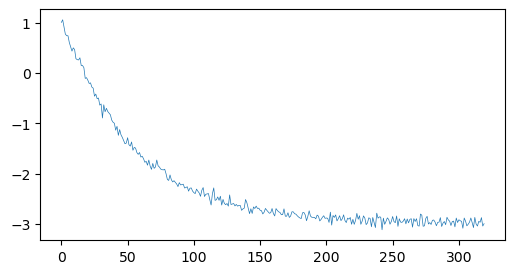

best val metric 1.342391554514567


In [9]:
def ate_rte(est, ref, hop=HOP_SEC, sec=RTE_SEC):
    ate = float(np.sqrt(((est - ref) ** 2).sum(1).mean()))
    w = max(int(round(sec / hop)), 1)
    rel = [
        np.linalg.norm((est[i + w] - est[i]) - (ref[i + w] - ref[i]))
        for i in range(0, len(est) - w, max(w // 2, 1))
    ]
    return ate, float(np.mean(rel)) if rel else float("nan")

def integrate_pos(vel_1s, pos0):
    n = len(vel_1s)
    out = np.zeros((n, 3), np.float32)
    out[0] = pos0
    for t in range(1, n):
        out[t] = out[t - 1] + vel_1s[t] * HOP_SEC
    return out

@torch.no_grad()
def predict(Xn, En):
    model.eval()
    mus = []
    for i in range(0, len(Xn), BATCH_SIZE):
        xb = torch.tensor(Xn[i:i + BATCH_SIZE], device=device)
        eb = torch.tensor(En[i:i + BATCH_SIZE], device=device)
        mu, _ = model(xb, eb)
        mus.append(denorm_t(mu).cpu().numpy())
    return np.concatenate(mus)

def apply_mu(ekf_p, ekf_q, mu):
    pos_c = ekf_p + mu[:, :3]
    q_c = q_normalize(q_mul(ekf_q, rotvec_to_quat(mu[:, 3:])))
    return pos_c, q_c

def split_score(Xn, En, ekf_p, ekf_q, pos_ref, q_ref):
    mu = predict(Xn, En)
    pos_c, q_c = apply_mu(ekf_p, ekf_q, mu)
    ate, _ = ate_rte(pos_c[::HOP_N], pos_ref[::HOP_N])
    return ate, float(q_ang_deg(q_c, q_ref).mean()), pos_c, q_c, mu

model = NoiseModel().to(device)
opt = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=8, factor=0.5)
losses, best, state = [], float("inf"), None

for e in range(EPOCHS):
    model.train()
    run = 0.0
    for xb, eb, yb in train_loader:
        xb, eb, yb = xb.to(device), eb.to(device), yb.to(device)
        mu, log_s = model(xb, eb)
        loss = nll(mu, log_s, yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        run += loss.item()
        losses.append(loss.item())
    ate_v, qv, _, _, _ = split_score(X_va_n, E_va, ekf_p_va, ekf_q_va, pos_va, q_va)
    metric = ate_v + qv / 30
    sched.step(metric)
    if metric < best:
        best = metric
        state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    if e % 5 == 0 or e == EPOCHS - 1:
        print(f"{e:3d}  train {run:.3f}  val ATE {ate_v:.3f} m  quat {qv:.2f}")

assert state is not None
model.load_state_dict(state)
plt.figure(figsize=(6, 3))
plt.plot(losses, lw=0.5)
plt.show()
print("best val metric", best)


In [10]:
pos_te_1s = pos_te[::HOP_N]
ate_c, quat_c, pos_c, q_c, mu_te = split_score(X_te_n, E_te, ekf_p_te, ekf_q_te, pos_te, q_te)
pos_c_1s = pos_c[::HOP_N]
ate_c, rte_c = ate_rte(pos_c_1s, pos_te_1s)
ate_e, rte_e = ate_rte(ekf_p_te[::HOP_N], pos_te_1s)
quat_e = float(q_ang_deg(ekf_q_te, q_te).mean())
pos_gps = integrate_pos(v_gps_te[::HOP_N], pos_te_1s[0])
ate_g, rte_g = ate_rte(pos_gps, pos_te_1s)
print(f"C0 EKF+μ   ATE {ate_c:.3f} m  RTE {rte_c:.3f} m  quat {quat_c:.2f} deg")
print(f"EKF raw    ATE {ate_e:.3f} m  RTE {rte_e:.3f} m  quat {quat_e:.2f} deg")
print(f"GPS vel    ATE {ate_g:.3f} m  RTE {rte_g:.3f} m")
print("mean |μ_pos|", float(np.linalg.norm(mu_te[:, :3], axis=1).mean()), "m  mean |μ_rot| deg", float(np.degrees(np.linalg.norm(mu_te[:, 3:], axis=1).mean())))

a8 = os.path.join(DATA, "results_a8q.json")
if os.path.exists(a8):
    a8j = json.load(open(a8))
    print(f"A8q (ref)  ATE {a8j['A']['ate_m']:.3f} m  RTE {a8j['A']['rte_m']:.3f} m  quat {a8j['A']['quat_mean_deg']:.2f} deg")


C0 EKF+μ   ATE 0.885 m  RTE 0.292 m  quat 5.44 deg
EKF raw    ATE 0.775 m  RTE 0.201 m  quat 7.46 deg
GPS vel    ATE 1.103 m  RTE 0.451 m
mean |μ_pos| 0.6994235515594482 m  mean |μ_rot| deg 2.044414758682251
A8q (ref)  ATE 1.119 m  RTE 0.312 m  quat 4.95 deg


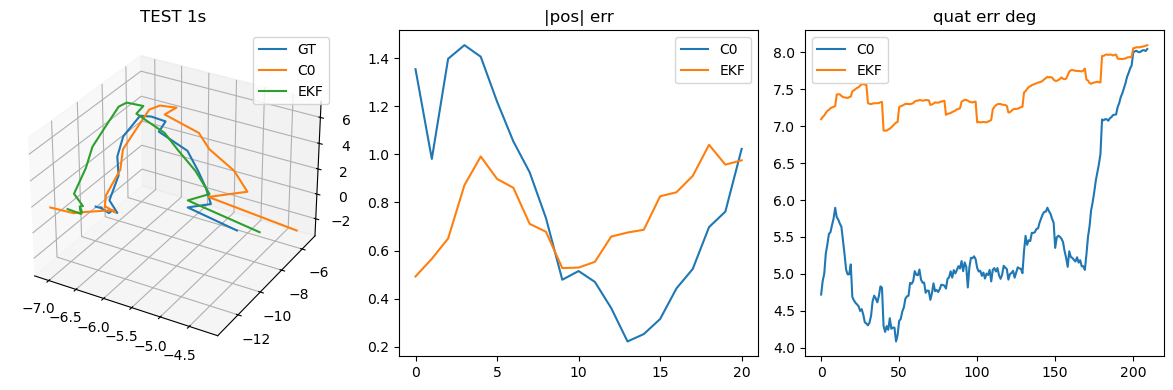

{
  "run_id": "C0_NLL",
  "kind": "ekf_residual_nll",
  "n_train": 961,
  "n_val": 210,
  "n_test": 210,
  "C": {
    "ate_m": 0.8854783773422241,
    "rte_m": 0.2923283576965332,
    "quat_mean_deg": 5.436652660369873
  },
  "EKF": {
    "ate_m": 0.7753929495811462,
    "rte_m": 0.2014169692993164,
    "quat_mean_deg": 7.457713603973389
  },
  "GPS_vel": {
    "ate_m": 1.1033438444137573,
    "rte_m": 0.4506833553314209
  }
}


In [11]:
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(131, projection="3d")
ax.plot(*pos_te_1s.T, label="GT")
ax.plot(*pos_c_1s.T, label="C0")
ax.plot(*ekf_p_te[::HOP_N].T, label="EKF")
ax.legend()
ax.set_title("TEST 1s")
ax2 = fig.add_subplot(132)
t1 = np.arange(len(pos_te_1s))
ax2.plot(t1, np.linalg.norm(pos_c_1s - pos_te_1s, axis=1), label="C0")
ax2.plot(t1, np.linalg.norm(ekf_p_te[::HOP_N] - pos_te_1s, axis=1), label="EKF")
ax2.legend()
ax2.set_title("|pos| err")
ax3 = fig.add_subplot(133)
ax3.plot(q_ang_deg(q_c, q_te), label="C0")
ax3.plot(q_ang_deg(ekf_q_te, q_te), label="EKF")
ax3.legend()
ax3.set_title("quat err deg")
plt.tight_layout()
plt.show()

results = {
    "run_id": "C0_NLL",
    "kind": "ekf_residual_nll",
    "n_train": int(len(X_tr)),
    "n_val": int(len(X_va)),
    "n_test": int(len(X_te)),
    "C": {"ate_m": float(ate_c), "rte_m": float(rte_c), "quat_mean_deg": quat_c},
    "EKF": {"ate_m": float(ate_e), "rte_m": float(rte_e), "quat_mean_deg": quat_e},
    "GPS_vel": {"ate_m": float(ate_g), "rte_m": float(rte_g)},
}
with open("results.json", "w") as f:
    json.dump(results, f, indent=2)
np.savez("results.npz", pos_te=pos_te_1s, pos_hat=pos_c_1s, pos_ekf=ekf_p_te[::HOP_N], q_te=q_te, q_hat=q_c, q_ekf=ekf_q_te)
fig.savefig("results.png", dpi=120)
torch.save(
    {
        "run_id": "C0_NLL",
        "state": model.state_dict(),
        "feat_mean": feat_mean, "feat_std": feat_std,
        "y_mean": y_mean, "y_std": y_std,
        "pos_m": pos_m, "pos_s": pos_s,
        "W": W, "stride": STRIDE,
    },
    "option_c.pth",
)
print(json.dumps(results, indent=2))
